# **Actividad 4.**

# Objetivo
# Identificar e implementar el modelo preentrenado más adecuado para un caso de uso específico.

# **CASO DE USO : DETECCION DE HUMO Y FUEGO MEDIENTE LA IMPLEMENTACION DE UN MODELO DE VISION ARTIFICIAL**

# CONFIGURACION DEL ENTORNO

In [ ]:


import sys
import platform
import torch

print("Versión de Python:", sys.version)
print("Sistema operativo:", platform.platform())
print("Versión de PyTorch:", torch.__version__)


if torch.cuda.is_available():
    print("\nGPU disponible:", torch.cuda.get_device_name(0))
    print("Versión CUDA de PyTorch:", torch.version.cuda)

    memoria = torch.cuda.get_device_properties(0).total_memory
    print(f"Memoria total de GPU: {memoria / (1024**3):.2f} GB")
else:
    print("\nNo se detectó una GPU.")
    print("Revisa la configuración del entorno de ejecución de Colab.")

# GPU ASISGNADA POR COLAB

# GPU disponible: Tesla T4
# Versión CUDA de PyTorch: 13.0
# Memoria total de GPU: 14.56 GB

# INSTALACION DE DEPENDENCIAS

In [ ]:

%pip install -q ultralytics huggingface_hub==1.23.0 datasets scikit-learn matplotlib pillow

In [ ]:
%pip install -q --upgrade "huggingface_hub>=1.31.0,<2.0" "transformers==5.18.0"

In [ ]:
import huggingface_hub
import transformers
import pandas
import pyarrow
import ultralytics
import torch

print("Hugging Face Hub:", huggingface_hub.__version__)
print("Transformers:", transformers.__version__)
print("Pandas:", pandas.__version__)
print("PyArrow:", pyarrow.__version__)
print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())

# AUTENTICACIÓN CON HUGGING FACE MEDIANTE UN TOKEN

In [ ]:
from huggingface_hub import login
from google.colab import userdata

try:
    token_hf = userdata.get("HF_TOKEN")

    if token_hf:
        login(token=token_hf)
        print("Autenticación con Hugging Face completada.")
    else:
        print("No se proporcionó un token.")

except Exception as error:
    print("No se pudo completar la autenticación.")
    print("Detalle:", str(error))
    print("Los modelos públicos pueden seguir siendo accesibles.")

# DESCARGA DEL CONJUNTO DE DATOS

**Resumen del conjunto de datos**

Este conjunto de datos contiene imágenes de columnas de humo y fuego. Las imágenes fueron tomadas de forma remota. El objetivo de este conjunto de datos es entrenar sistemas de visión artificial para detectar incendios forestales.

**LINK :** https://huggingface.co/datasets/odiug77/wildfire

In [ ]:

from datasets import load_dataset

nombre_dataset = "odiug77/wildfire"

dataset = load_dataset(nombre_dataset)

print("Dataset cargado correctamente.")
print("\nEstructura del dataset:")
print(dataset)

print("\nParticiones disponibles:")
print(list(dataset.keys()))

for nombre_split, datos in dataset.items():
    print(f"\nPartición: {nombre_split}")
    print("Número de ejemplos:", len(datos))
    print("Columnas:", datos.column_names)
    print("Características:")
    print(datos.features)

# EXPLORACION DEL CONJUNTO DE DATOS

In [ ]:

from datasets import load_dataset

dataset = load_dataset("odiug77/wildfire")

print("Estructura del dataset:")
print(dataset)

datos = dataset["train"]

print("\nNúmero de imágenes:", len(datos))
print("\nColumnas:", datos.column_names)
print("\nCaracterísticas:")
print(datos.features)

print("\nPrimer registro:")
print(datos[0])


VISUALIZACION DE ALGUNAS IMAGENES

In [ ]:

import matplotlib.pyplot as plt
import random

datos = dataset["train"]
indices = random.sample(range(len(datos)), 6)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, idx in zip(axes.flat, indices):
    ax.imshow(datos[idx]["image"])
    ax.set_title(f"Imagen {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from huggingface_hub import HfApi

api = HfApi()
repo_id = "odiug77/wildfire"

archivos = api.list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

print("Archivos disponibles en el repositorio:")
for archivo in archivos:
    print(archivo)


In [ ]:

from huggingface_hub import HfApi, hf_hub_download

repo_id = "odiug77/wildfire"
api = HfApi()

archivos = api.list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

# Mostrar archivos de configuración y algunas etiquetas
print("Archivos de configuración:")
for archivo in archivos:
    if archivo.endswith((".yaml", ".yml", ".names")):
        print(archivo)

labels = [
    archivo for archivo in archivos
    if "/yololabels/" in archivo and archivo.endswith(".txt")
]

print("\nCantidad de archivos de etiquetas:", len(labels))
print("\nPrimeras etiquetas:")

for archivo in labels[:5]:
    ruta = hf_hub_download(
        repo_id=repo_id,
        filename=archivo,
        repo_type="dataset"
    )
    print(f"\nArchivo: {archivo}")
    with open(ruta, "r") as f:
        print(f.read()[:1000] or "(archivo vacío)")


In [ ]:
from huggingface_hub import hf_hub_download

for classes_file in classes_files:
    path = hf_hub_download(
        repo_id="odiug77/wildfire",
        filename=classes_file,
        repo_type="dataset"
    )

    print(f"\nArchivo: {classes_file}")

    with open(path, "r") as f:
        contenido = f.read().strip()

    print(contenido)

In [ ]:

from huggingface_hub import snapshot_download
from pathlib import Path

# Descargar de nuevo el repositorio completo
ruta_dataset = snapshot_download(
    repo_id="odiug77/wildfire",
    repo_type="dataset"
)

base = Path(ruta_dataset)
print("Dataset descargado en:", base)

# Localizar las carpetas originales
for carpeta in base.rglob("*"):
    if carpeta.is_dir() and carpeta.name.lower() in {
        "images", "yololabels", "labels"
    }:
        archivos = [p for p in carpeta.iterdir() if p.is_file()]
        print(f"{carpeta} -> {len(archivos)} archivos")


In [ ]:

from pathlib import Path

base = Path(ruta_dataset)
extensiones = {".jpg", ".jpeg", ".png", ".webp"}

carpetas_labels = [
    p for p in base.rglob("*")
    if p.is_dir() and p.name.lower() == "yololabels"
]

if not carpetas_labels:
    raise FileNotFoundError(
        "No se encontró la carpeta yololabels. "
        "Revisa las carpetas mostradas en el paso 1."
    )

# Usar la carpeta de etiquetas del conjunto train
carpeta_labels = next(
    (p for p in carpetas_labels if "train" in p.parts),
    carpetas_labels[0]
)

# La carpeta images normalmente es hermana de yololabels
carpeta_images = carpeta_labels.parent / "images"

if not carpeta_images.is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta de imágenes: {carpeta_images}"
    )

archivos_img = [
    p for p in carpeta_images.iterdir()
    if p.is_file() and p.suffix.lower() in extensiones
]
archivos_lbl = list(carpeta_labels.glob("*.txt"))

# Mantener el formato de tu código anterior:
# (ruta del repositorio, ruta local)
imagenes_locales = [
    (str(p.relative_to(base)), str(p))
    for p in archivos_img
]
etiquetas_locales = [
    (str(p.relative_to(base)), str(p))
    for p in archivos_lbl
]

print("Carpeta de imágenes:", carpeta_images)
print("Carpeta de etiquetas:", carpeta_labels)
print("Imágenes encontradas:", len(imagenes_locales))
print("Etiquetas encontradas:", len(etiquetas_locales))


In [ ]:
print("Imágenes:", len(imagenes_locales))
print("Etiquetas:", len(etiquetas_locales))
print("Primeras etiquetas:", etiquetas_locales[:3])

EXPLORACIÓN DEL ARCHIVO README

In [ ]:

from huggingface_hub import hf_hub_download

readme_path = hf_hub_download(
    repo_id="odiug77/wildfire",
    filename="README.md",
    repo_type="dataset"
)

with open(readme_path, "r", encoding="utf-8") as f:
    readme = f.read()

print(readme[:12000] if readme else "El README está vacío.")


OBSERVAR SI TODAS LAS IMAGENES TIENEN UNA ETIQUETA ESTABLECIDA

In [ ]:

from collections import Counter

imagenes_repo = [
    f for f in archivos
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

etiquetas_repo = [
    f for f in archivos
    if "/yololabels/" in f.lower()
    and f.lower().endswith(".txt")
    and not f.lower().endswith("classes.txt")
]

print("Imágenes en el repositorio:", len(imagenes_repo))
print("Archivos de anotaciones YOLO:", len(etiquetas_repo))

print("\nEjemplos de imágenes:")
for f in imagenes_repo[:5]:
    print(f)

print("\nEjemplos de etiquetas:")
for f in etiquetas_repo[:5]:
    print(f)


# PRIMER MODELO

Modelo de detección de incendios y humo en tiempo real basado en YOLOv26 (Ultralytics). Alcanza un 94,9 % de mAP@50 en tareas de detección de incendios y humo.

**Descripción del modelo**

Este modelo detecta fuego, humo e indicadores relacionados con incendios en imágenes y vídeos. Está basado en la arquitectura YOLOv26-S y entrenado con 8939 imágenes anotadas.

**Clases**
fuego - llamas activas
humo - columnas de humo
otros - Indicadores de incendio relacionados

Nombre del repositorio : "SalahALHaismawi/yolov26-fire-detection"

Link : https://huggingface.co/SalahALHaismawi/yolov26-fire-detection


In [ ]:

%pip install -q ultralytics huggingface_hub datasets


In [ ]:

from huggingface_hub import hf_hub_download
from ultralytics import YOLO
import torch

repositorio = "SalahALHaismawi/yolov26-fire-detection"

ruta_modelo = hf_hub_download(
    repo_id=repositorio,
    filename="best.pt"
)

modelo = YOLO(ruta_modelo)

print("Modelo cargado correctamente.")
print("Ruta:", ruta_modelo)
print("Clases del modelo:", modelo.names)
print("GPU disponible:", torch.cuda.is_available())


# PREPARACIÓN DEL CONJUNTO DE DATOS PARA INGRESARLO AL MODELO

In [ ]:

from pathlib import Path
from huggingface_hub import try_to_load_from_cache

repo_id = "odiug77/wildfire"

# Recuperar archivos del repositorio desde la caché local
imagenes_locales = []
etiquetas_locales = []

for archivo in imagenes_repo:
    ruta = try_to_load_from_cache(
        repo_id=repo_id,
        filename=archivo,
        repo_type="dataset"
    )
    if isinstance(ruta, str):
        imagenes_locales.append((archivo, Path(ruta)))

for archivo in etiquetas_repo:
    ruta = try_to_load_from_cache(
        repo_id=repo_id,
        filename=archivo,
        repo_type="dataset"
    )
    if isinstance(ruta, str):
        etiquetas_locales.append((archivo, Path(ruta)))

print("Imágenes disponibles en caché:", len(imagenes_locales))
print("Etiquetas disponibles en caché:", len(etiquetas_locales))

if imagenes_locales:
    print("Ejemplo de imagen:", imagenes_locales[0][1])
if etiquetas_locales:
    print("Ejemplo de etiqueta:", etiquetas_locales[0][1])


In [ ]:

from pathlib import Path
import os
import yaml

# Directorio temporal para el benchmark
raiz_eval = Path("/content/sylva_eval")
carpeta_img = raiz_eval / "images"
carpeta_lbl = raiz_eval / "labels"

carpeta_img.mkdir(parents=True, exist_ok=True)
carpeta_lbl.mkdir(parents=True, exist_ok=True)

# Mapas de archivos disponibles en caché
mapa_img_local = {
    Path(repo_path).stem: local_path
    for repo_path, local_path in imagenes_locales
}
mapa_lbl_local = {
    Path(repo_path).stem: local_path
    for repo_path, local_path in etiquetas_locales
}

incluidas = 0
excluidas = 0

for nombre, ruta_img in mapa_img_local.items():

    # Solo imágenes con etiqueta existente
    if nombre not in mapa_lbl_local:
        excluidas += 1
        continue

    ruta_lbl = mapa_lbl_local[nombre]

    with open(ruta_lbl, "r", encoding="utf-8") as f:
        lineas = [linea.strip() for linea in f if linea.strip()]

    # Excluir etiquetas vacías hasta verificar que sean negativos reales
    if not lineas:
        excluidas += 1
        continue

    nuevas_lineas = []
    valido = True

    for linea in lineas:
        partes = linea.split()

        if len(partes) != 5:
            valido = False
            break

        clase_original = int(partes[0])

        # Dataset: 0=smoke, 1=fire
        # Modelo:  0=fire, 1=other, 2=smoke
        conversion = {0: 2, 1: 0}

        if clase_original not in conversion:
            valido = False
            break

        partes[0] = str(conversion[clase_original])
        nuevas_lineas.append(" ".join(partes))

    if not valido:
        excluidas += 1
        continue

    destino_img = carpeta_img / Path(nombre + ".jpg")
    destino_lbl = carpeta_lbl / Path(nombre + ".txt")

    # Crear enlaces a los archivos originales en caché
    if not destino_img.exists():
        os.symlink(ruta_img, destino_img)

    destino_lbl.write_text(
        "\n".join(nuevas_lineas) + "\n",
        encoding="utf-8"
    )

    incluidas += 1

# Configuración para Ultralytics
config = {
    "path": str(raiz_eval),
    "val": "images",
    "names": {
        0: "fire",
        1: "other",
        2: "smoke"
    }
}

ruta_yaml = raiz_eval / "dataset.yaml"
ruta_yaml.write_text(
    yaml.safe_dump(config, sort_keys=False),
    encoding="utf-8"
)

print("Imágenes preparadas:", incluidas)
print("Imágenes excluidas:", excluidas)
print("Configuración:", ruta_yaml)
print("Clases:", config["names"])


In [ ]:

from pathlib import Path
import shutil
import yaml

# ============================================================
# 1. VERIFICAR LOS ARCHIVOS ORIGINALES
# ============================================================

print("Imágenes disponibles en origen:", len(imagenes_locales))
print("Etiquetas disponibles en origen:", len(etiquetas_locales))

# Crear mapas por nombre de archivo, sin extensión
mapa_img_local = {
    Path(repo_path).stem: Path(local_path)
    for repo_path, local_path in imagenes_locales
}

mapa_lbl_local = {
    Path(repo_path).stem: Path(local_path)
    for repo_path, local_path in etiquetas_locales
}

print("Imágenes únicas:", len(mapa_img_local))
print("Etiquetas únicas:", len(mapa_lbl_local))

# ============================================================
# 2. PREPARAR CARPETAS LIMPIAS
# ============================================================

raiz_eval = Path("/content/sylva_eval")
carpeta_img = raiz_eval / "images"
carpeta_lbl = raiz_eval / "labels"

# Eliminar las carpetas anteriores para evitar archivos
# antiguos o enlaces rotos que alteren el conteo.
if raiz_eval.exists():
    shutil.rmtree(raiz_eval)

carpeta_img.mkdir(parents=True)
carpeta_lbl.mkdir(parents=True)

# ============================================================
# 3. CONVERSIÓN DE CLASES PARA EL MODELO 1
# ============================================================

# Dataset original:
# 0 = smoke
# 1 = fire
#
# Modelo 1:
# 0 = fire
# 1 = other
# 2 = smoke

conversion = {
    0: 2,  # smoke -> smoke
    1: 0   # fire  -> fire
}

incluidas = 0
sin_etiqueta = 0
etiquetas_vacias = 0
invalidas = 0
archivos_inexistentes = 0

# ============================================================
# 4. VALIDAR Y COPIAR IMÁGENES Y ETIQUETAS
# ============================================================

for nombre, ruta_img in sorted(mapa_img_local.items()):

    # Comprobar que la imagen realmente exista
    if not ruta_img.is_file():
        archivos_inexistentes += 1
        continue

    # Debe existir el archivo de etiquetas correspondiente
    ruta_lbl = mapa_lbl_local.get(nombre)

    if ruta_lbl is None or not ruta_lbl.is_file():
        sin_etiqueta += 1
        continue

    lineas = [
        linea.strip()
        for linea in ruta_lbl.read_text(
            encoding="utf-8"
        ).splitlines()
        if linea.strip()
    ]

    # Excluir etiquetas vacías para este benchmark
    if not lineas:
        etiquetas_vacias += 1
        continue

    nuevas_lineas = []
    valido = True

    for linea in lineas:
        partes = linea.split()

        if len(partes) != 5:
            valido = False
            break

        try:
            clase_original = int(partes[0])
        except ValueError:
            valido = False
            break

        if clase_original not in conversion:
            valido = False
            break

        # Comprobar que las coordenadas sean numéricas
        try:
            coordenadas = [float(x) for x in partes[1:]]
        except ValueError:
            valido = False
            break

        # Comprobar formato YOLO normalizado
        if not all(0 <= x <= 1 for x in coordenadas):
            valido = False
            break

        partes[0] = str(conversion[clase_original])
        nuevas_lineas.append(" ".join(partes))

    if not valido:
        invalidas += 1
        continue

    # Conservar la extensión original de la imagen
    extension = ruta_img.suffix.lower()
    destino_img = carpeta_img / f"{nombre}{extension}"
    destino_lbl = carpeta_lbl / f"{nombre}.txt"

    # Copiar imagen físicamente
    shutil.copy2(ruta_img, destino_img)

    # Guardar las etiquetas convertidas
    destino_lbl.write_text(
        "\n".join(nuevas_lineas) + "\n",
        encoding="utf-8"
    )

    incluidas += 1

# ============================================================
# 5. CREAR CONFIGURACIÓN PARA ULTRALYTICS
# ============================================================

config = {
    "path": str(raiz_eval),
    "train": "images",
    "val": "images",
    "names": {
        0: "fire",
        1: "other",
        2: "smoke"
    }
}

ruta_yaml = raiz_eval / "dataset.yaml"

ruta_yaml.write_text(
    yaml.safe_dump(config, sort_keys=False),
    encoding="utf-8"
)

# ============================================================
# 6. VERIFICACIÓN FINAL
# ============================================================

total_imagenes = sum(
    1 for p in carpeta_img.iterdir()
    if p.is_file()
)

total_etiquetas = len(list(carpeta_lbl.glob("*.txt")))

print("\n========== RESUMEN DEL DATASET ==========")
print("Imágenes incluidas:", incluidas)
print("Imágenes copiadas:", total_imagenes)
print("Etiquetas creadas:", total_etiquetas)
print("Sin etiqueta:", sin_etiqueta)
print("Etiquetas vacías:", etiquetas_vacias)
print("Anotaciones inválidas:", invalidas)
print("Archivos de imagen inexistentes:", archivos_inexistentes)
print("YAML:", ruta_yaml)

# No continuar silenciosamente con un dataset incompleto
if incluidas != 1807:
    raise RuntimeError(
        f"Se esperaban 1807 imágenes válidas, "
        f"pero se prepararon {incluidas}. "
        "Revisa los archivos originales y los contadores."
    )

print("\nCorrecto: se prepararon las 1807 imágenes esperadas.")


In [ ]:

from pathlib import Path
import yaml

raiz_eval = Path("/content/sylva_eval")

config = {
    "path": str(raiz_eval),
    "train": "images",
    "val": "images",
    "names": {
        0: "fire",
        1: "other",
        2: "smoke"
    }
}

ruta_yaml = raiz_eval / "dataset.yaml"
ruta_yaml.write_text(
    yaml.safe_dump(config, sort_keys=False),
    encoding="utf-8"
)

print(ruta_yaml.read_text())


# **IMPLEMENTACION DEL MODELO**

In [ ]:

import torch
from pathlib import Path

assert "modelo" in globals(), (
    "cargar el modelo YOLOv26."
)

print("GPU:", torch.cuda.get_device_name(0))
print("Modelo:", modelo.names)

resultados = modelo.val(
    data=str(ruta_yaml),
    imgsz=640,
    batch=16,
    device=0,
    conf=0.001,
    iou=0.6,
    plots=True,
    verbose=True
)

print("\n--- MÉTRICAS DEL MODELO 1 ---")
print("Precision:", resultados.box.mp)
print("Recall:", resultados.box.mr)
print("mAP@50:", resultados.box.map50)
print("mAP@50:95:", resultados.box.map)


# --- MÉTRICAS DEL MODELO 1 ---
Precision: 0.9672099592395413

Recall: 0.5

mAP@50: 0.5549999999999999

mAP@50:95: 0.166375

# OBSERVACION DE PREDICCIONES REALIZADAS POR EL MODELO

In [ ]:

import random
from pathlib import Path
from IPython.display import display

imagenes = sorted(carpeta_img.glob("*.jpg"))

random.seed(42)
muestra = random.sample(imagenes, min(12, len(imagenes)))

predicciones = modelo.predict(
    source=[str(p) for p in muestra],
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content/sylva_revision",
    name="muestra_modelo1",
    exist_ok=True,
    verbose=False
)

print("Imágenes revisadas:", len(predicciones))
print("Resultados guardados en /content/sylva_revision/muestra_modelo1")

for resultado in predicciones[:12]:
    print("\nArchivo:", Path(resultado.path).name)
    print("Clases detectadas:", [
        modelo.names[int(c)]
        for c in resultado.boxes.cls
    ])
    display(resultado.plot())


In [ ]:

print("Modelo 1:", modelo.names)
print("Dataset:", ruta_yaml)
print("Imágenes de evaluación:", len(list(carpeta_img.glob("*.jpg"))))
print("GPU:", torch.cuda.get_device_name(0))


# SEGUNDO MODELO

Modelo Detector de incendios y humo (ajuste fino D-Fire)
YOLOv8n se ha optimizado con el conjunto de datos D-Fire para la detección de humo y fuego en imágenes.

Clases

0- Humo

1- fuego

Metricas
mAP50	0.754

mAP50-95	0.430

Precision	0.766

Recall	0.688

Nombre del repositorio :"rabahdev/fire-smoke-yolov8n"

LINK :https://huggingface.co/rabahdev/fire-smoke-yolov8n

In [ ]:

from huggingface_hub import hf_hub_download
from ultralytics import YOLO
from pathlib import Path
import yaml

repositorio2 = "rabahdev/fire-smoke-yolov8n"

ruta_modelo2 = hf_hub_download(
    repo_id=repositorio2,
    filename="best.pt"
)

modelo2 = YOLO(ruta_modelo2)

print("Modelo 2 cargado:", modelo2.names)
print("GPU disponible:", torch.cuda.is_available())


# PREPARACIÓN DEL CONJUNTO DE DATOS PARA INGRESARLO AL MODELO

In [ ]:

from pathlib import Path

raiz_eval2 = Path("/content/sylva_eval_model2")
carpeta_img2 = raiz_eval2 / "images"
carpeta_lbl2 = raiz_eval2 / "labels"

carpeta_img2.mkdir(parents=True, exist_ok=True)
carpeta_lbl2.mkdir(parents=True, exist_ok=True)

# En el dataset actual:
# 0 = fire y 2 = smoke
# En el modelo 2:
# 0 = smoke y 1 = fire
conversion2 = {0: 1, 2: 0}

for imagen in sorted(carpeta_img.glob("*.jpg")):
    etiqueta = carpeta_lbl / f"{imagen.stem}.txt"

    if not etiqueta.exists():
        continue

    lineas_nuevas = []

    for linea in etiqueta.read_text(encoding="utf-8").splitlines():
        if not linea.strip():
            continue

        partes = linea.split()
        clase = int(partes[0])

        if clase not in conversion2:
            raise ValueError(
                f"Clase inesperada {clase} en {etiqueta}"
            )

        partes[0] = str(conversion2[clase])
        lineas_nuevas.append(" ".join(partes))

    destino_img = carpeta_img2 / imagen.name
    destino_lbl = carpeta_lbl2 / etiqueta.name

    if not destino_img.exists():
        destino_img.symlink_to(imagen)

    destino_lbl.write_text(
        "\n".join(lineas_nuevas) + "\n",
        encoding="utf-8"
    )

config2 = {
    "path": str(raiz_eval2),
    "train": "images",
    "val": "images",
    "names": {
        0: "smoke",
        1: "fire"
    }
}

ruta_yaml2 = raiz_eval2 / "dataset.yaml"
ruta_yaml2.write_text(
    yaml.safe_dump(config2, sort_keys=False),
    encoding="utf-8"
)

print("Imágenes para modelo 2:", len(list(carpeta_img2.glob("*.jpg"))))
print("Configuración:", ruta_yaml2)


# **IMPLEMENTACION DEL MODELO**

In [ ]:

resultados2 = modelo2.val(
    data=str(ruta_yaml2),
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    conf=0.001,
    iou=0.6,
    plots=True,
    verbose=True
)

print("\n--- MÉTRICAS DEL MODELO 2 ---")
print(f"Precision: {resultados2.box.mp:.4f}")
print(f"Recall:    {resultados2.box.mr:.4f}")
print(f"mAP@50:    {resultados2.box.map50:.4f}")
print(f"mAP@50:95: {resultados2.box.map:.4f}")
print("mAP por clase:", resultados2.box.maps)


--- MÉTRICAS DEL MODELO 2 ---

Precision: 0.8589

Recall:    0.8849

mAP@50:    0.8950

mAP@50:95: 0.6777

mAP por clase: [    0.45983      0.8955]

# OBSERVACION DE PREDICCIONES REALIZADAS POR EL MODELO

In [ ]:
import random
from pathlib import Path
from IPython.display import display

imagenes = sorted(carpeta_img.glob("*.jpg"))

random.seed(42)
muestra = random.sample(imagenes, min(12, len(imagenes)))

predicciones = modelo2.predict(
    source=[str(p) for p in muestra],
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content/sylva_revision",
    name="muestra_modelo2",
    exist_ok=True,
    verbose=False
)

print("Imágenes revisadas:", len(predicciones))
print("Resultados guardados en /content/sylva_revision/muestra_modelo2")

for resultado in predicciones[:12]:
    print("\nArchivo:", Path(resultado.path).name)
    print("Clases detectadas:", [
        modelo.names[int(c)]
        for c in resultado.boxes.cls
    ])
    display(resultado.plot())

# **TERCER MODELO**

Fuego y humo tempranos (YOLOv8)
Un detector YOLOv8n optimizado para incendios domésticos y humo en sus primeras etapas : escenarios de cocina, electricidad y cigarrillos. Forma parte de la colección Model Garden de modelos de visión artificial optimizados.

Clases
fire,smoke

Nombre del repositorio: "Farhatullah0066/yolov8n-fire-smoke-detection"

Link :https://huggingface.co/mfranzon/fire-smoke-yolov8

In [ ]:

from huggingface_hub import hf_hub_download
from ultralytics import YOLO
import torch

repositorio3 = "Farhatullah0066/yolov8n-fire-smoke-detection"

ruta_modelo3 = hf_hub_download(
    repo_id=repositorio3,
    filename="best.pt",
    repo_type="model"
)

print("Archivo descargado:", ruta_modelo3)

modelo3 = YOLO(ruta_modelo3)

print("Clases del modelo 3:", modelo3.names)
print("GPU disponible:", torch.cuda.is_available())


# PREPARACIÓN DEL CONJUNTO DE DATOS PARA INGRESARLO AL MODELO

In [ ]:

from pathlib import Path
import yaml

raiz_eval3 = Path("/content/sylva_eval_model3")
carpeta_img3 = raiz_eval3 / "images"
carpeta_lbl3 = raiz_eval3 / "labels"

carpeta_img3.mkdir(parents=True, exist_ok=True)
carpeta_lbl3.mkdir(parents=True, exist_ok=True)

# Dataset actual -> modelo 3
# 0 fire  -> 1 fire
# 2 smoke -> 0 smoke
conversion3 = {0: 1, 2: 0}

for imagen in sorted(carpeta_img.glob("*.jpg")):
    etiqueta = carpeta_lbl / f"{imagen.stem}.txt"

    if not etiqueta.exists():
        continue

    lineas_nuevas = []

    for linea in etiqueta.read_text(encoding="utf-8").splitlines():
        if not linea.strip():
            continue

        partes = linea.split()
        clase = int(partes[0])

        if clase not in conversion3:
            raise ValueError(
                f"Clase inesperada {clase} en {etiqueta}"
            )

        partes[0] = str(conversion3[clase])
        lineas_nuevas.append(" ".join(partes))

    destino_img = carpeta_img3 / imagen.name
    destino_lbl = carpeta_lbl3 / etiqueta.name

    if not destino_img.exists():
        destino_img.symlink_to(imagen)

    # Reescribir las etiquetas para garantizar el orden correcto
    destino_lbl.write_text(
        "\n".join(lineas_nuevas) + "\n",
        encoding="utf-8"
    )

config3 = {
    "path": str(raiz_eval3),
    "train": "images",
    "val": "images",
    "names": {
        0: "smoke",
        1: "fire"
    }
}

ruta_yaml3 = raiz_eval3 / "dataset.yaml"
ruta_yaml3.write_text(
    yaml.safe_dump(config3, sort_keys=False),
    encoding="utf-8"
)

print("Imágenes preparadas:", len(list(carpeta_img3.glob("*.jpg"))))
print("Clases del modelo:", modelo3.names)
print("Configuración:", ruta_yaml3)


# **IMPLEMENTACION DEL MODELO**

In [ ]:

resultados3 = modelo3.val(
    data=str(ruta_yaml3),
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    conf=0.001,
    iou=0.6,
    plots=True,
    verbose=True
)

print("\n--- MÉTRICAS DEL MODELO 3 ---")
print(f"Precisión: {resultados3.box.mp:.4f}")
print(f"Recall:    {resultados3.box.mr:.4f}")
print(f"mAP@50:    {resultados3.box.map50:.4f}")
print(f"mAP@50-95: {resultados3.box.map:.4f}")
print("mAP por clase:", resultados3.box.maps)


--- MÉTRICAS DEL MODELO 3 ---

Precisión: 0.9080

Recall:    0.8000

mAP@50:    0.8521

mAP@50-95: 0.7174

mAP por clase: [    0.53931      0.8955]

# OBSERVACION DE PREDICCIONES REALIZADAS POR EL MODELO

In [ ]:
import random
from pathlib import Path
from IPython.display import display

imagenes = sorted(carpeta_img.glob("*.jpg"))

random.seed(42)
muestra = random.sample(imagenes, min(12, len(imagenes)))

predicciones = modelo3.predict(
    source=[str(p) for p in muestra],
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content/sylva_revision",
    name="muestra_modelo3",
    exist_ok=True,
    verbose=False
)

print("Imágenes revisadas:", len(predicciones))
print("Resultados guardados en /content/sylva_revision/muestra_modelo3")

for resultado in predicciones[:12]:
    print("\nArchivo:", Path(resultado.path).name)
    print("Clases detectadas:", [
        modelo.names[int(c)]
        for c in resultado.boxes.cls
    ])
    display(resultado.plot())


# **Resumen de metricas obtenidas**

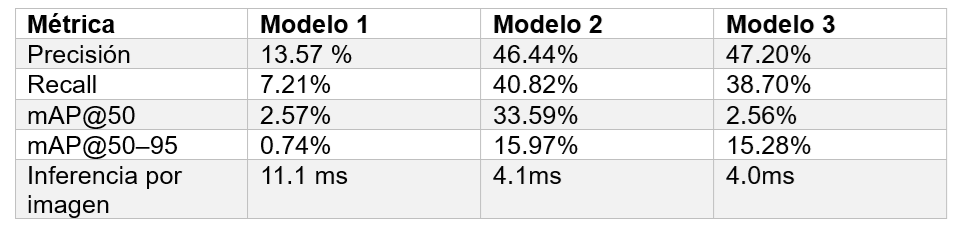

**# Interpretación de resultados.**

# Modelo 1: Presenta un rendimiento muy bajo. Su recall de 7.21% indica que recupera solo una pequeña proporción de los objetos anotados

#  Modelo 2: Obtiene el mejor recall, el mayor mAP@50 y el mayor mAP@50–95. También tiene un tiempo de inferencia bajo. Es el mejor candidato inicial para continuar las pruebas.

# Modelo 3: Consigue la mayor precisión global, por un margen pequeño frente al Modelo 2, y una inferencia ligeramente más rápida. Sin embargo, su recall es menor, por lo que deja sin detectar más objetos.
